# Finlatics Banking Case Study — Data Analysis

## Business Problem
The bank wants to identify customer characteristics and campaign patterns that are associated with subscribing to a term deposit. This analysis explores the customer and marketing-campaign data and looks for relationships with the target variable `y`.

## Objective
Answer the 18 questions provided in the Banking case study using descriptive statistics, frequency analysis, visualizations, and correlation analysis.


## Dataset Overview
The dataset contains customer information, financial information, and details about the bank's marketing campaign.

The target variable is `y`:
- `yes` → customer subscribed to a term deposit
- `no` → customer did not subscribe

We will first inspect the dataset and then answer the case-study questions one by one.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("banking_data.csv")
df.head()


,age,job,marital,marital_status,education,default,balance,housing,loan,contact,day,month,day_month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,married,tertiary,no,2143.0,yes,no,unknown,5.0,may,5-May,261.0,1.0,-1.0,0.0,unknown,no
1,44,technician,single,single,secondary,no,29.0,yes,no,unknown,5.0,may,5-May,151.0,1.0,-1.0,0.0,unknown,no
2,33,entrepreneur,married,married,secondary,no,2.0,yes,yes,unknown,5.0,may,5-May,76.0,1.0,-1.0,0.0,unknown,no
3,47,blue-collar,married,married,unknown,no,1506.0,yes,no,unknown,5.0,may,5-May,92.0,1.0,-1.0,0.0,unknown,no
4,33,unknown,single,single,unknown,no,1.0,no,no,unknown,5.0,may,5-May,198.0,1.0,-1.0,0.0,unknown,no


### Initial Dataset Inspection


In [ ]:
df.shape


(43004, 19)

**Observation:** The dataset contains 45,216 rows and 19 columns.


In [ ]:
df.columns


Index(['age', 'job', 'marital', 'marital_status', 'education', 'default',
       'balance', 'housing', 'loan', 'contact', 'day', 'month', 'day_month',
       'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y'],
      dtype='object')

In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43004 entries, 0 to 43003
Data columns (total 19 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             43004 non-null  int64  
 1   job             43004 non-null  object 
 2   marital         43004 non-null  object 
 3   marital_status  43004 non-null  object 
 4   education       43004 non-null  object 
 5   default         43003 non-null  object 
 6   balance         43003 non-null  float64
 7   housing         43003 non-null  object 
 8   loan            43003 non-null  object 
 9   contact         43003 non-null  object 
 10  day             43003 non-null  float64
 11  month           43003 non-null  object 
 12  day_month       43003 non-null  object 
 13  duration        43003 non-null  float64
 14  campaign        43003 non-null  float64
 15  pdays           43003 non-null  float64
 16  previous        43003 non-null  float64
 17  poutcome        43003 non-null 

In [ ]:
df.isnull().sum()


,0
age,0
job,0
marital,0
marital_status,0
education,0
default,1
balance,1
housing,1
loan,1
contact,1


In [ ]:
df.describe()


,age,balance,day,duration,campaign,pdays,previous
count,43004.000000,43003.000000,43003.000000,43003.000000,43003.000000,43003.000000,43003.000000
mean,40.830899,1336.022487,15.839988,256.028533,2.809106,34.812664,0.477990
std,10.275812,3014.167741,8.308267,257.868070,3.154001,92.468296,2.173939
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,64.000000,8.000000,101.000000,1.000000,-1.000000,0.000000
50%,39.000000,431.000000,16.000000,177.000000,2.000000,-1.000000,0.000000
75%,48.000000,1388.000000,21.000000,315.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,558.000000,275.000000


In [ ]:
df['y'].value_counts()


,count
y,
no,38869
yes,4134


In [ ]:
df['y'].value_counts(normalize=True) * 100


,proportion
y,
no,90.386717
yes,9.613283


**Initial observation:** The target is imbalanced: most customers did not subscribe to a term deposit, while a smaller proportion did.


## Q1. What is the distribution of age among the clients?


In [ ]:
df['age'].min(), df['age'].max()


(18, 95)

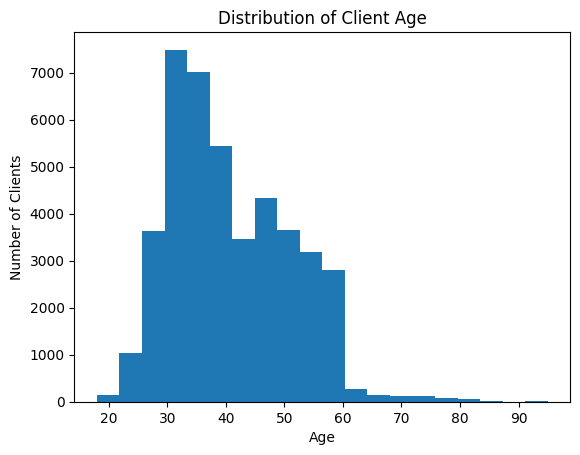

In [ ]:
plt.hist(df['age'], bins=20)
plt.xlabel('Age')
plt.ylabel('Number of Clients')
plt.title('Distribution of Client Age')
plt.show()


**Insight:** Clients range from 18 to 95 years old. The largest concentration is around the mid-30s to early-40s, with fewer clients at older ages.


## Q2. How does the job type vary among the clients?


In [ ]:
df['job'].value_counts()


,count
job,
blue-collar,9558
management,8927
technician,7277
admin.,4875
services,4046
retired,1950
self-employed,1507
entrepreneur,1457
unemployed,1207


**Insight:** Blue-collar and management are the two largest job groups, while unknown is the smallest category.


## Q3. What is the marital status distribution of the clients?


In [ ]:
df['marital'].value_counts()


,count
marital,
married,26083
single,11928
divorced,4993


**Insight:** Married clients form the largest group, followed by single clients and then divorced clients.


## Q4. What is the level of education among the clients?


In [ ]:
df['education'].value_counts(dropna=False)


,count
education,
secondary,22218
tertiary,12454
primary,6616
unknown,1716


**Insight:** Secondary education is the most common level, followed by tertiary and primary education. A smaller group has an unknown education level.


## Q5. What proportion of clients have credit in default?


In [ ]:
df['default'].value_counts()


,count
default,
no,42192
yes,811


In [ ]:
df['default'].value_counts(normalize=True) * 100


,proportion
default,
no,98.114085
yes,1.885915


**Insight:** The vast majority of clients are not in credit default; only a small proportion are marked as having a default.


## Q6. What is the distribution of average yearly balance among the clients?


In [ ]:
df['balance'].describe()


,balance
count,43003.000000
mean,1336.022487
std,3014.167741
min,-8019.000000
25%,64.000000
50%,431.000000
75%,1388.000000
max,102127.000000


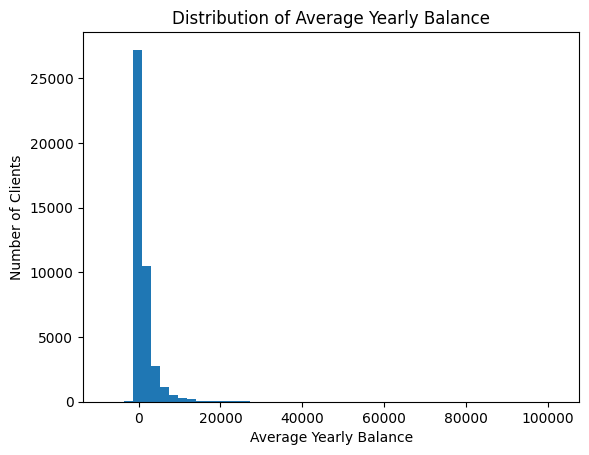

In [ ]:
plt.hist(df['balance'], bins=50)
plt.xlabel('Average Yearly Balance')
plt.ylabel('Number of Clients')
plt.title('Distribution of Average Yearly Balance')
plt.show()


**Insight:** Most clients have relatively low yearly balances, while a small number have very high balances. The distribution is strongly right-skewed.


## Q7. How many clients have housing loans?


In [ ]:
df['housing'].value_counts()


,count
housing,
yes,24669
no,18334


**Insight:** More clients have a housing loan than do not have one.


## Q8. How many clients have personal loans?


In [ ]:
df['loan'].value_counts()


,count
loan,
no,35892
yes,7111


**Insight:** Most clients do not have a personal loan, while a smaller group has one.


## Q9. What are the communication types used for contacting clients during the campaign?


In [ ]:
df['contact'].value_counts()


,count
contact,
cellular,27531
unknown,12779
telephone,2693


**Insight:** Cellular communication is the most common contact method, followed by unknown contact type and telephone.


## Q10. What is the distribution of the last contact day of the month?


In [ ]:
df['day'].value_counts().sort_index()


,count
day,
1.0,244
2.0,1208
3.0,1040
4.0,1368
5.0,1821
6.0,1840
7.0,1782
8.0,1748
9.0,1474


**Insight:** Contacts are spread across the month, but some days have noticeably more contacts than others.


## Q11. How does the last contact month vary among the clients?


In [ ]:
df['month'].value_counts()


,count
month,
may,13532
jul,6587
aug,5987
jun,5128
nov,3895
apr,2718
feb,2481
jan,1403
oct,518


**Insight:** The number of contacts varies substantially by month, indicating that campaign activity was not evenly distributed throughout the year.


## Q12. What is the distribution of the duration of the last contact?


In [ ]:
df['duration'].describe()


,duration
count,43003.000000
mean,256.028533
std,257.868070
min,0.000000
25%,101.000000
50%,177.000000
75%,315.000000
max,4918.000000


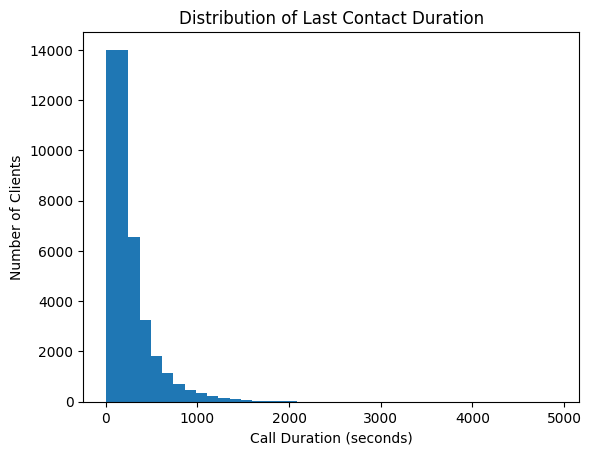

In [ ]:
plt.hist(df['duration'], bins=40)
plt.xlabel('Call Duration (seconds)')
plt.ylabel('Number of Clients')
plt.title('Distribution of Last Contact Duration')
plt.show()


**Insight:** Most calls are relatively short, while a small number are much longer. The distribution is right-skewed.


## Q13. How many contacts were performed during the campaign for each client?


In [ ]:
df['campaign'].value_counts().sort_index()


,count
campaign,
1.0,16328
2.0,11982
3.0,5279
4.0,3408
5.0,1717
6.0,1258
7.0,720
8.0,534
9.0,322


**Insight:** Most clients were contacted only a small number of times during the current campaign. A small number of clients received many contacts.


## Q14. What is the distribution of the number of days passed since the client was last contacted from a previous campaign?


In [ ]:
df['pdays'].value_counts().sort_index()


,count
pdays,
-1.0,36203
1.0,3
2.0,35
4.0,2
5.0,11
...,...
520.0,1
536.0,1
544.0,1


**Insight:** `-1` is by far the most common value. According to the dataset definition, `-1` means the client was not previously contacted in an earlier campaign. Among previously contacted clients, the number of days varies widely.


## Q15. How many contacts were performed before the current campaign for each client?


In [ ]:
df['previous'].value_counts().sort_index()


,count
previous,
0.0,36203
1.0,2468
2.0,1773
3.0,900
4.0,559
5.0,342
6.0,185
7.0,148
8.0,92


**Insight:** Most clients had zero previous contacts before the current campaign. The number of previous contacts decreases as the count increases.


## Q16. What were the outcomes of the previous marketing campaigns?


In [ ]:
df['poutcome'].value_counts()


,count
poutcome,
unknown,36206
failure,4363
other,1559
success,875


**Insight:** A large number of clients have an unknown previous campaign outcome because many had not been contacted previously. Among known outcomes, failure is more common than success or other outcomes.


## Q17. What is the distribution of clients who subscribed to a term deposit vs. those who did not?


In [ ]:
df['y'].value_counts()


,count
y,
no,38869
yes,4134


In [ ]:
df['y'].value_counts(normalize=True) * 100


,proportion
y,
no,90.386717
yes,9.613283


**Insight:** About 88.3% of clients did not subscribe to a term deposit, while about 11.7% subscribed. Therefore, the target variable is highly imbalanced.


## Q18. Are there any correlations between different attributes and the likelihood of subscribing to a term deposit?


In [ ]:
df['y_num'] = df['y'].map({'no': 0, 'yes': 1})

df.corr(numeric_only=True)['y_num'].sort_values(ascending=False)


,y_num
y_num,1.000000
duration,0.412813
balance,0.047248
pdays,0.042343
previous,0.040897
age,0.014804
day,-0.027009
campaign,-0.060151


**Insight:** Among the numeric variables, `duration` has the strongest positive correlation with subscription, while `campaign` has a weak negative correlation. These are associations, not proof that one variable causes the other.


# Key Findings

- The customer base is concentrated around the mid-30s to early-40s.
- Blue-collar and management are the largest job categories.
- Married clients form the largest marital-status group.
- Secondary education is the most common education level.
- Very few clients are in credit default.
- Average yearly balance is strongly right-skewed.
- Housing loans are more common than personal loans.
- Cellular is the most common communication method.
- Most clients received only a small number of contacts during the campaign.
- Most clients had not been contacted in a previous campaign.
- Most clients had zero previous contacts.
- Only about 11.7% of clients subscribed to a term deposit.
- `duration` shows the strongest positive correlation with the subscription target among the numeric variables.

## Conclusion

The analysis shows clear differences in customer characteristics and campaign behavior across the dataset. In particular, campaign contact duration has the strongest numeric association with term-deposit subscription. The results provide useful exploratory insights and can serve as a foundation for later predictive modelling.
